# Student Performance Analysis

## 1. Project Objective

The objective of this project is to explore student
academic performance using the UCI Student Performance
dataset.

We will investigate relationships between student
demographics, study habits, family background,
school-related factors and final academic grades.

## 2. Dataset Source

UCI Machine Learning Repository:
Student Performance

Subject: Portuguese
Target of interest: G3 (final grade)

In [1]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

student_performance = fetch_ucirepo(id=320)

X = student_performance.data.features
y = student_performance.data.targets

print("Features shape:", X.shape)
print("Targets shape:", y.shape)

Features shape: (649, 30)
Targets shape: (649, 3)


In [2]:
display(student_performance.variables)

,name,role,type,demographic,description,units,missing_values
0,school,Feature,Categorical,NaN,student's school (binary: 'GP' - Gabriel Perei...,None,no
1,sex,Feature,Binary,Sex,student's sex (binary: 'F' - female or 'M' - m...,None,no
2,age,Feature,Integer,Age,student's age (numeric: from 15 to 22),None,no
3,address,Feature,Categorical,NaN,student's home address type (binary: 'U' - urb...,None,no
4,famsize,Feature,Categorical,Other,family size (binary: 'LE3' - less or equal to ...,None,no
5,Pstatus,Feature,Categorical,Other,parent's cohabitation status (binary: 'T' - li...,None,no
6,Medu,Feature,Integer,Education Level,"mother's education (numeric: 0 - none, 1 - pr...",None,no
7,Fedu,Feature,Integer,Education Level,"father's education (numeric: 0 - none, 1 - pr...",None,no
8,Mjob,Feature,Categorical,Occupation,"mother's job (nominal: 'teacher', 'health' car...",None,no
9,Fjob,Feature,Categorical,Occupation,"father's job (nominal: 'teacher', 'health' car...",None,no


In [3]:
X.shape

(649, 30)

In [4]:
y.shape

(649, 3)

In [5]:
X.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,yes,no,no,4,3,4,1,1,3,4
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,yes,no,5,3,3,1,1,3,2
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,yes,no,4,3,2,2,3,3,6
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,yes,3,2,2,1,1,5,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,yes,no,no,4,3,2,1,2,5,0


In [6]:
y.head()

,G1,G2,G3
0,0,11,11
1,9,11,11
2,12,13,12
3,14,14,14
4,11,13,13


In [7]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 30 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [8]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("Feature columns:", len(X.columns))
print("Target columns:", len(y.columns))

X shape: (649, 30)
y shape: (649, 3)
Feature columns: 30
Target columns: 3


In [9]:
print("Target column names:", y.columns.tolist())

Target column names: ['G1', 'G2', 'G3']


In [10]:
for column in X.columns:
    print(column)

school
sex
age
address
famsize
Pstatus
Medu
Fedu
Mjob
Fjob
reason
guardian
traveltime
studytime
failures
schoolsup
famsup
paid
activities
nursery
higher
internet
romantic
famrel
freetime
goout
Dalc
Walc
health
absences


In [11]:
print("Data types:")
display(X.dtypes.value_counts())

print("Numerical columns:")
print(X.select_dtypes(include="number").columns.tolist())

print("Categorical columns:")
print(X.select_dtypes(include=["object", "category", "string"]).columns.tolist())

Data types:


str      17
int64    13
Name: count, dtype: int64

Numerical columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
Categorical columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [12]:
for column in X.columns:
    print(f"\n{column}")
    print(X[column].value_counts().sort_index())


school
school
GP    423
MS    226
Name: count, dtype: int64

sex
sex
F    383
M    266
Name: count, dtype: int64

age
age
15    112
16    177
17    179
18    140
19     32
20      6
21      2
22      1
Name: count, dtype: int64

address
address
R    197
U    452
Name: count, dtype: int64

famsize
famsize
GT3    457
LE3    192
Name: count, dtype: int64

Pstatus
Pstatus
A     80
T    569
Name: count, dtype: int64

Medu
Medu
0      6
1    143
2    186
3    139
4    175
Name: count, dtype: int64

Fedu
Fedu
0      7
1    174
2    209
3    131
4    128
Name: count, dtype: int64

Mjob
Mjob
at_home     135
health       48
other       258
services    136
teacher      72
Name: count, dtype: int64

Fjob
Fjob
at_home      42
health       23
other       367
services    181
teacher      36
Name: count, dtype: int64

reason
reason
course        285
home          149
other          72
reputation    143
Name: count, dtype: int64

guardian
guardian
father    153
mother    455
other      41
Name: count,

In [13]:
ordinal_columns = [
    "Medu", "Fedu", "traveltime", "studytime",
    "famrel", "freetime", "goout",
    "Dalc", "Walc", "health"
]

for column in ordinal_columns:
    print(f"\n{column}:")
    print(sorted(X[column].unique()))


Medu:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Fedu:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

traveltime:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

studytime:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

famrel:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

freetime:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

goout:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Dalc:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Walc:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

health:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [14]:
binary_columns = [
    "schoolsup", "famsup", "paid", "activities",
    "nursery", "higher", "internet", "romantic"
]

for column in binary_columns:
    print(f"\n{column}:")
    print(X[column].value_counts())


schoolsup:
schoolsup
no     581
yes     68
Name: count, dtype: int64

famsup:
famsup
yes    398
no     251
Name: count, dtype: int64

paid:
paid
no     610
yes     39
Name: count, dtype: int64

activities:
activities
no     334
yes    315
Name: count, dtype: int64

nursery:
nursery
yes    521
no     128
Name: count, dtype: int64

higher:
higher
yes    580
no      69
Name: count, dtype: int64

internet:
internet
yes    498
no     151
Name: count, dtype: int64

romantic:
romantic
no     410
yes    239
Name: count, dtype: int64


In [15]:
# Missing values in features
print("Missing values in X:")
display(X.isnull().sum().sort_values(ascending=False))

# Missing values in targets
print("Missing values in y:")
display(y.isnull().sum().sort_values(ascending=False))

# Total missing values
print("Total missing in X:", X.isnull().sum().sum())
print("Total missing in y:", y.isnull().sum().sum())

Missing values in X:


school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
dtype: int64

Missing values in y:


G1    0
G2    0
G3    0
dtype: int64

Total missing in X: 0
Total missing in y: 0


In [16]:
missing_percentage = (
    X.isnull().mean() * 100
).sort_values(ascending=False)

display(missing_percentage)

school        0.0
sex           0.0
age           0.0
address       0.0
famsize       0.0
Pstatus       0.0
Medu          0.0
Fedu          0.0
Mjob          0.0
Fjob          0.0
reason        0.0
guardian      0.0
traveltime    0.0
studytime     0.0
failures      0.0
schoolsup     0.0
famsup        0.0
paid          0.0
activities    0.0
nursery       0.0
higher        0.0
internet      0.0
romantic      0.0
famrel        0.0
freetime      0.0
goout         0.0
Dalc          0.0
Walc          0.0
health        0.0
absences      0.0
dtype: float64

In [17]:
print("Duplicate feature rows:", X.duplicated().sum())

complete_dataset = pd.concat([X, y], axis=1)

print("Duplicate complete records:", complete_dataset.duplicated().sum())

Duplicate feature rows: 0
Duplicate complete records: 0


In [18]:
display(X.dtypes)
display(y.dtypes)

school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
dtype: object

G1    int64
G2    int64
G3    int64
dtype: object

In [19]:
columns_to_check = [
    "sex",
    "school",
    "address",
    "famsize",
    "internet",
    "higher",
    "studytime",
    "traveltime"
]

for column in columns_to_check:
    print(f"\n{column}:")
    print(sorted(X[column].unique()))


sex:
['F', 'M']

school:
['GP', 'MS']

address:
['R', 'U']

famsize:
['GT3', 'LE3']

internet:
['no', 'yes']

higher:
['no', 'yes']

studytime:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

traveltime:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [20]:
print("Age range:")
print(X["age"].min(), X["age"].max())

print("\nAbsences range:")
print(X["absences"].min(), X["absences"].max())

print("\nFailures range:")
print(X["failures"].min(), X["failures"].max())

print("\nGrade ranges:")
display(y.agg(["min", "max"]))

Age range:
15 22

Absences range:
0 32

Failures range:
0 3

Grade ranges:


,G1,G2,G3
min,0,0,0
max,19,19,19


In [21]:
invalid_grades = y[
    (y < 0) | (y > 20)
]

print("Invalid grade values:")
display(invalid_grades)

Invalid grade values:


,G1,G2,G3
0,NaN,NaN,NaN
1,NaN,NaN,NaN
2,NaN,NaN,NaN
3,NaN,NaN,NaN
4,NaN,NaN,NaN
...,...,...,...
644,NaN,NaN,NaN
645,NaN,NaN,NaN
646,NaN,NaN,NaN
647,NaN,NaN,NaN


In [22]:
display(X[["age", "absences", "failures"]].describe())

,age,absences,failures
count,649.000000,649.000000,649.000000
mean,16.744222,3.659476,0.221880
std,1.218138,4.640759,0.593235
min,15.000000,0.000000,0.000000
25%,16.000000,0.000000,0.000000
50%,17.000000,2.000000,0.000000
75%,18.000000,6.000000,0.000000
max,22.000000,32.000000,3.000000


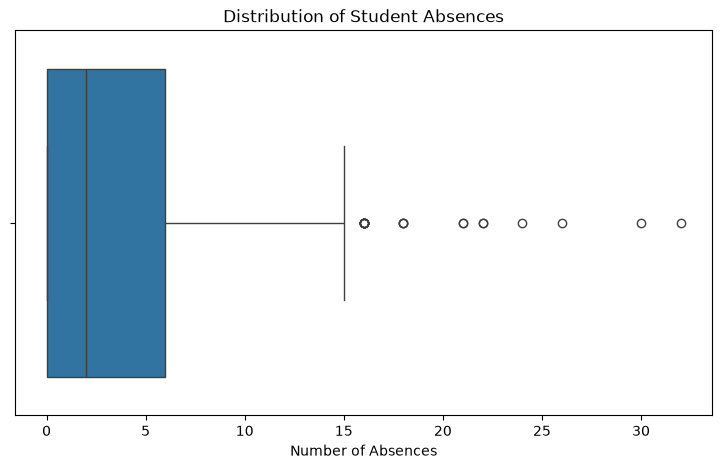

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(data=X, x="absences")

plt.title("Distribution of Student Absences")
plt.xlabel("Number of Absences")

plt.show()

In [24]:
print("Students with zero grades:")

for column in y.columns:
    zero_count = (y[column] == 0).sum()

    print(f"{column}: {zero_count}")

Students with zero grades:
G1: 1
G2: 7
G3: 15


In [25]:
Q1 = X["absences"].quantile(0.25)
Q3 = X["absences"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers = X[
    (X["absences"] < lower_bound) |
    (X["absences"] > upper_bound)
]

display(outliers[["age", "absences", "failures"]])

Q1: 0.0
Q3: 6.0
IQR: 6.0
Lower bound: -9.0
Upper bound: 15.0


,age,absences,failures
40,16,16,0
103,15,16,0
150,15,24,0
155,17,22,0
161,16,16,0
197,17,32,0
206,17,16,0
211,16,16,0
212,17,30,1
217,17,21,0


## Data Quality Assessment — Findings

### Missing Values
No missing values were identified in the feature or target datasets.

### Duplicate Records
No duplicate feature rows or complete records were identified.

### Categorical Validation
The inspected categorical variables contained expected values according to the dataset documentation.

### Numerical Validation
- Age ranged from 15 to 22.
- Absences ranged from 0 to 32.
- Failures ranged from 0 to 3.
- Grades ranged from 0 to 19, within the documented 0–20 grading scale.

### Statistical Observations
- Student ages were relatively concentrated around 17 years.
- Absences showed considerable variation, with the mean exceeding the median.
- Most students had zero previous class failures.
- High absence values require further investigation as potential statistical outliers.

### Conclusion
The dataset contains no identified missing values or duplicate records. The inspected categorical values and numerical ranges appear valid. Potential outliers will be investigated rather than automatically removed.

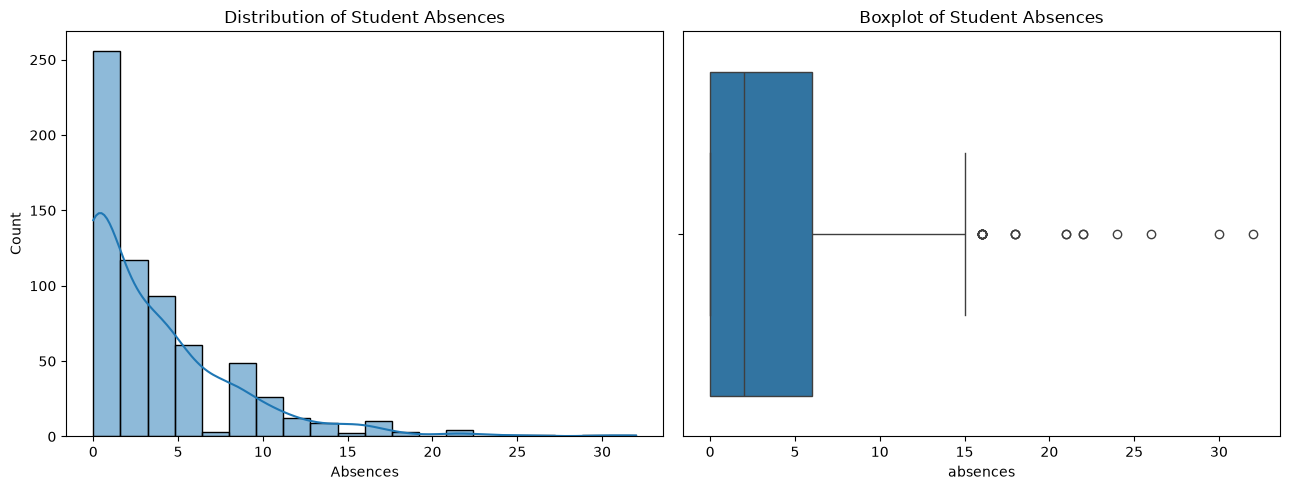

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=X,
    x="absences",
    bins=20,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Student Absences")
axes[0].set_xlabel("Absences")

sns.boxplot(
    data=X,
    x="absences",
    ax=axes[1]
)

axes[1].set_title("Boxplot of Student Absences")

plt.tight_layout()
plt.show()

In [27]:
zero_grade_students = complete_dataset[
    (complete_dataset["G1"] == 0) |
    (complete_dataset["G2"] == 0) |
    (complete_dataset["G3"] == 0)
]

display(
    zero_grade_students[
        ["age", "studytime", "failures", "absences",
         "G1", "G2", "G3"]
    ]
)

,age,studytime,failures,absences,G1,G2,G3
0,18,2,0,4,0,11,11
163,18,1,2,0,11,9,0
440,16,2,0,0,7,0,0
519,16,2,0,0,8,7,0
563,17,1,1,0,7,0,0
567,18,1,1,0,4,0,0
583,18,1,1,0,8,6,0
586,17,2,0,0,8,8,0
597,18,2,1,0,9,0,0
603,18,2,0,0,5,0,0


### Investigation of Zero Grades

The dataset contains:
- 1 student with a zero in G1.
- 7 students with a zero in G2.
- 15 students with a zero in G3.

These values were retained because zero may represent a legitimate recorded grade rather than missing data.

### Investigation of Absence Outliers

Using the 1.5 × IQR method:
- Q1 = 0
- Q3 = 6
- IQR = 6
- Lower bound = -9
- Upper bound = 15

A total of 21 observations were flagged as potential outliers.

These records represent students with unusually high absence counts. They were not automatically removed because statistical outliers are not necessarily data errors.

### Data Quality Decision

No missing values, duplicate records or confirmed invalid values were identified in the checks performed.

Potential outliers and zero grades were retained for further analysis.

In [28]:
final_grades = y["G3"]

print("Mean:", final_grades.mean())
print("Median:", final_grades.median())
print("Mode:", final_grades.mode().tolist())
print("Standard deviation:", final_grades.std())
print("Variance:", final_grades.var())
print("Minimum:", final_grades.min())
print("Maximum:", final_grades.max())
display(final_grades.describe())

Mean: 11.906009244992296
Median: 12.0
Mode: [11]
Standard deviation: 3.230656242804805
Variance: 10.437139759173657
Minimum: 0
Maximum: 19


count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: G3, dtype: float64

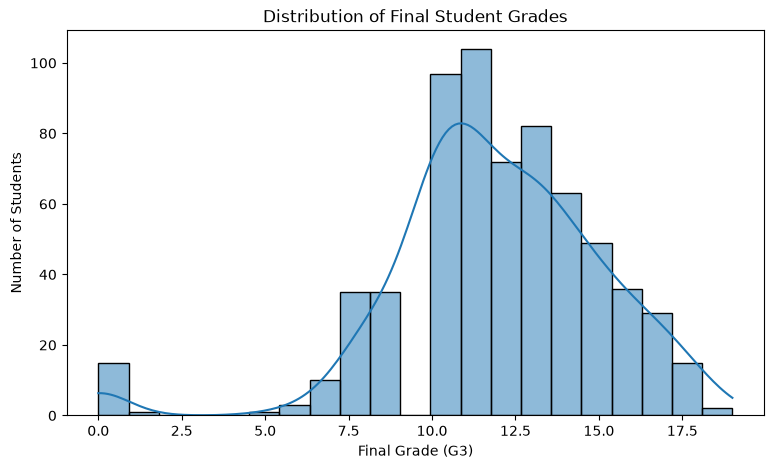

In [29]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=y,
    x="G3",
    bins=21,
    kde=True
)

plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()

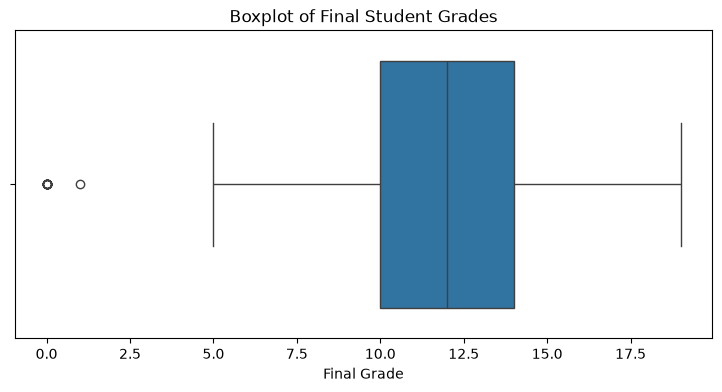

In [30]:
plt.figure(figsize=(9, 4))

sns.boxplot(data=y, x="G3")

plt.title("Boxplot of Final Student Grades")
plt.xlabel("Final Grade")

plt.show()

In [31]:
grade_categories = pd.cut(
    final_grades,
    bins=[-1, 9, 13, 16, 20],
    labels=["Low", "Moderate", "Good", "Excellent"]
)

print(grade_categories.value_counts().sort_index())

G3
Low          100
Moderate     355
Good         148
Excellent     46
Name: count, dtype: int64


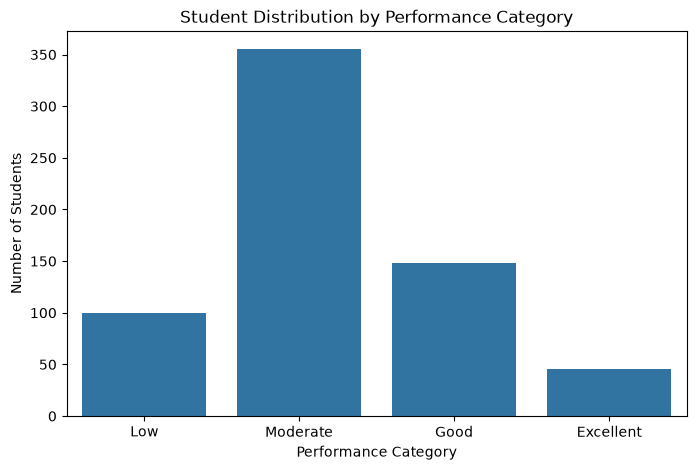

In [32]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x=grade_categories,
    order=["Low", "Moderate", "Good", "Excellent"]
)

plt.title("Student Distribution by Performance Category")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")

plt.show()

### Univariate Analysis — Final Grades (G3)

The final grade variable has the following descriptive statistics:

- Mean: 11.91
- Median: 12
- Mode: 11
- Standard deviation: 3.23
- Minimum: 0
- Maximum: 19

The average final grade is approximately 11.91 out of 20. The median is 12, indicating that the central tendency is close to the average.

The histogram shows that student grades are concentrated primarily in the middle range, particularly around 10–14.

The standard deviation indicates noticeable variation in academic performance across students.

The distribution's skewness should be assessed using the calculated skewness statistic and histogram rather than inferred from the mean and median alone.

In [33]:
numerical_columns = [
    "age", "absences", "failures", "studytime"
]

display(X[numerical_columns].describe())

,age,absences,failures,studytime
count,649.000000,649.000000,649.000000,649.000000
mean,16.744222,3.659476,0.221880,1.930663
std,1.218138,4.640759,0.593235,0.829510
min,15.000000,0.000000,0.000000,1.000000
25%,16.000000,0.000000,0.000000,1.000000
50%,17.000000,2.000000,0.000000,2.000000
75%,18.000000,6.000000,0.000000,2.000000
max,22.000000,32.000000,3.000000,4.000000


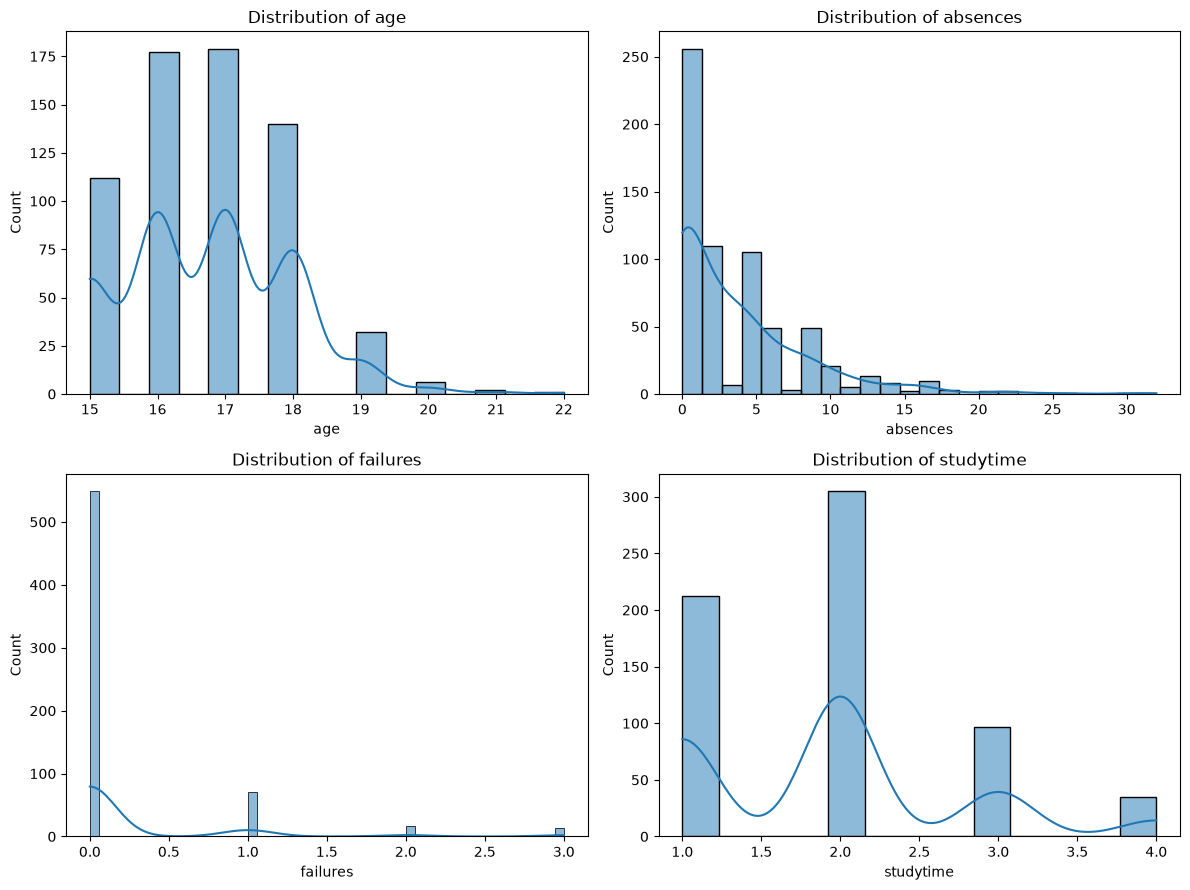

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for column, ax in zip(numerical_columns, axes.flatten()):
    sns.histplot(data=X, x=column, kde=True, ax=ax)
    ax.set_title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

### Numerical Feature Distribution — Findings

- **Age:** Students are concentrated around ages 16–18.
- **Absences:** The distribution is right-skewed. Most students have relatively few absences, while a small number have considerably higher absence counts.
- **Failures:** The distribution is heavily concentrated at zero, indicating that the vast majority of students have no previous class failures.
- **Study Time:** Study time is recorded in four ordinal categories, so its values represent ordered ranges rather than exact hours.

These distributions help identify patterns and potential relationships worth investigating. They do not establish causal relationships with final grades.

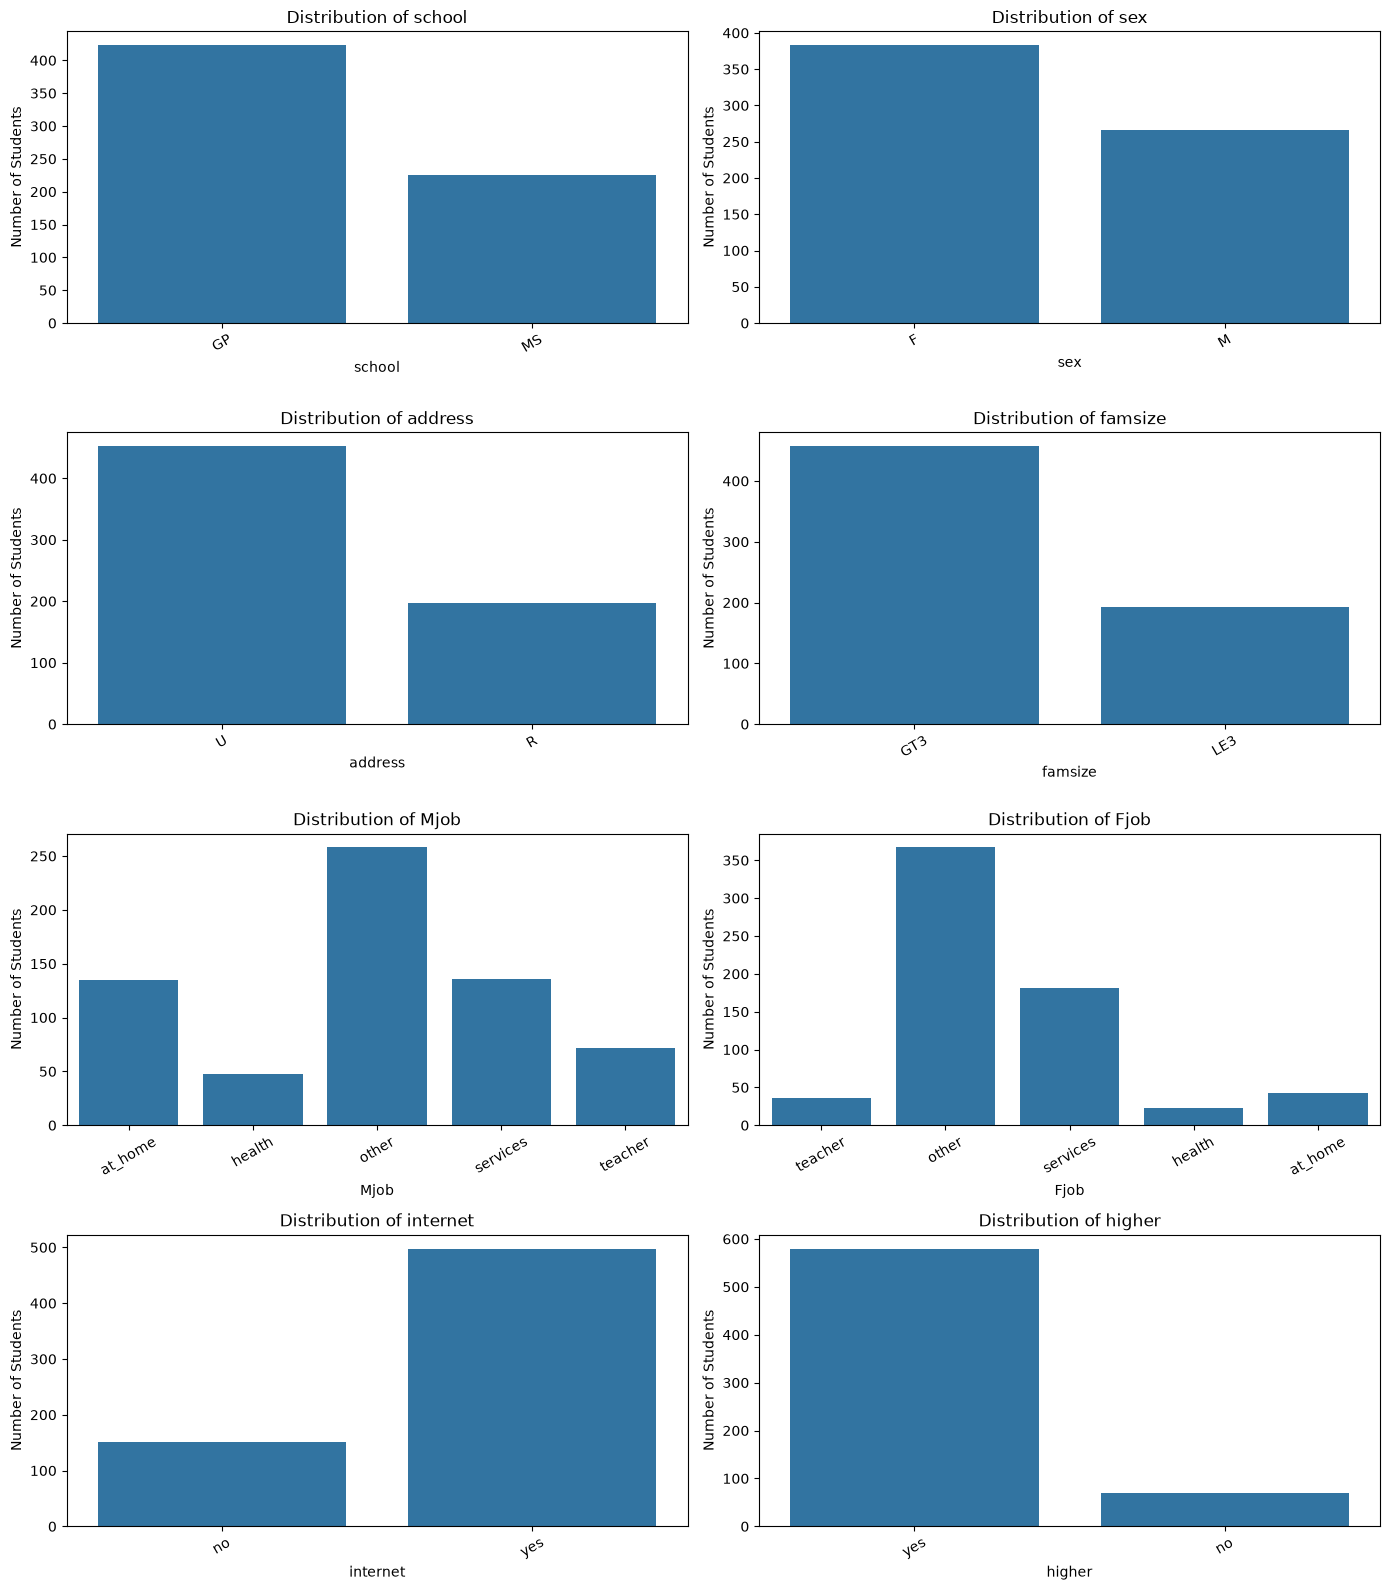

In [35]:
categorical_columns = [
    "school",
    "sex",
    "address",
    "famsize",
    "Mjob",
    "Fjob",
    "internet",
    "higher"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for column, ax in zip(categorical_columns, axes.flatten()):
    sns.countplot(data=X, x=column, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Students")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Categorical Feature Distribution — Findings

- **School:** Gabriel Pereira (GP) has more students than Mousinho da Silveira (MS).
- **Address:** Urban (U) students make up the majority of the dataset compared with rural (R) students.
- **Internet Access:** More students have internet access at home than those without it.

These observations describe the composition of the dataset. They do not establish whether school, residential location, or internet access affects academic performance.

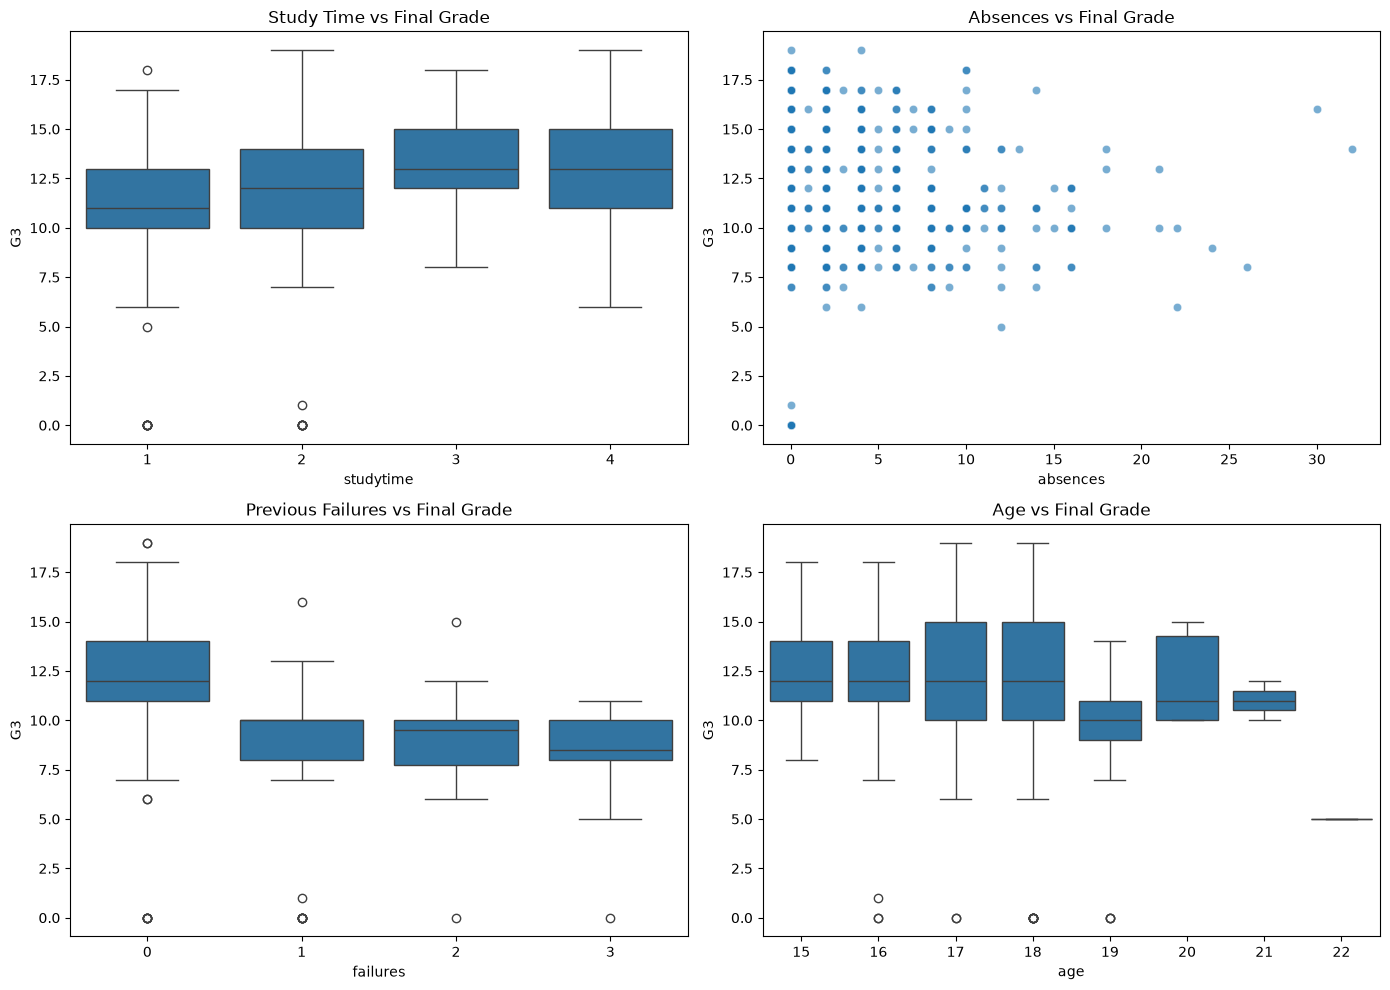

In [36]:
# Combine features and target for easier visualization
analysis_df = X.copy()
analysis_df["G3"] = y["G3"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Study time vs final grade
sns.boxplot(data=analysis_df, x="studytime", y="G3", ax=axes[0, 0])
axes[0, 0].set_title("Study Time vs Final Grade")

# Absences vs final grade
sns.scatterplot(data=analysis_df, x="absences", y="G3", alpha=0.6, ax=axes[0, 1])
axes[0, 1].set_title("Absences vs Final Grade")

# Previous failures vs final grade
sns.boxplot(data=analysis_df, x="failures", y="G3", ax=axes[1, 0])
axes[1, 0].set_title("Previous Failures vs Final Grade")

# Age vs final grade
sns.boxplot(data=analysis_df, x="age", y="G3", ax=axes[1, 1])
axes[1, 1].set_title("Age vs Final Grade")

plt.tight_layout()
plt.show()

In [37]:
print("Average G3 by Study Time:")
display(analysis_df.groupby("studytime")["G3"].agg(["count", "mean", "median"]))

print("Average G3 by Previous Failures:")
display(analysis_df.groupby("failures")["G3"].agg(["count", "mean", "median"]))

Average G3 by Study Time:


,count,mean,median
studytime,,,
1,212,10.844340,11.0
2,305,12.091803,12.0
3,97,13.226804,13.0
4,35,13.057143,13.0


Average G3 by Previous Failures:


,count,mean,median
failures,,,
0,549,12.510018,12.0
1,70,8.642857,10.0
2,16,8.812500,9.5
3,14,8.071429,8.5


### Bivariate Analysis — Numerical Features vs Final Grade (G3)

1. **Study Time:** Students in higher study-time categories generally have higher final grades. This suggests a positive association between study time and academic performance.

2. **Previous Failures:** Students with more previous failures generally have lower final grades. Previous academic difficulties may be associated with poorer subsequent performance.

3. **Absences:** The scatterplot shows considerable variation in final grades across absence counts. There is no strong, clear pattern visible.

4. **Age:** No clear relationship between age and final grades is apparent.

These observations indicate possible predictive relationships, but correlation does not establish causation. Other variables may also influence academic performance.

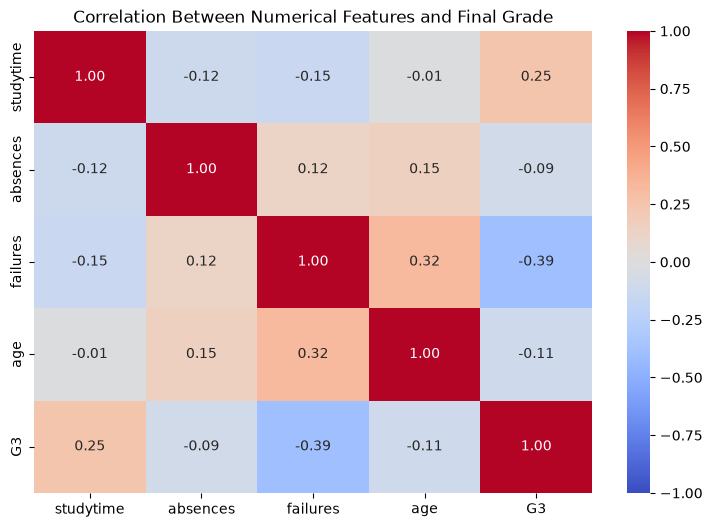

G3           1.000000
studytime    0.249789
absences    -0.091379
age         -0.106505
failures    -0.393316
Name: G3, dtype: float64

In [38]:
correlation = analysis_df[
    ["studytime", "absences", "failures", "age", "G3"]
].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features and Final Grade")
plt.show()

display(correlation["G3"].sort_values(ascending=False))

### Correlation Analysis — Numerical Features vs G3

| Feature | Correlation with G3 | Interpretation |
|---|---:|---|
| Study time | +0.25 | Weak positive relationship |
| Absences | -0.09 | Very weak negative relationship |
| Failures | -0.39 | Moderate negative relationship |
| Age | -0.11 | Very weak negative relationship |

**Key observations:**

- Previous failures have the strongest linear association with final grades among the four examined features.
- Study time has a weak positive association with final grades.
- Absences and age have very weak negative associations.
- These correlations do not establish causation.
- Correlation measures linear association and may not capture nonlinear relationships.

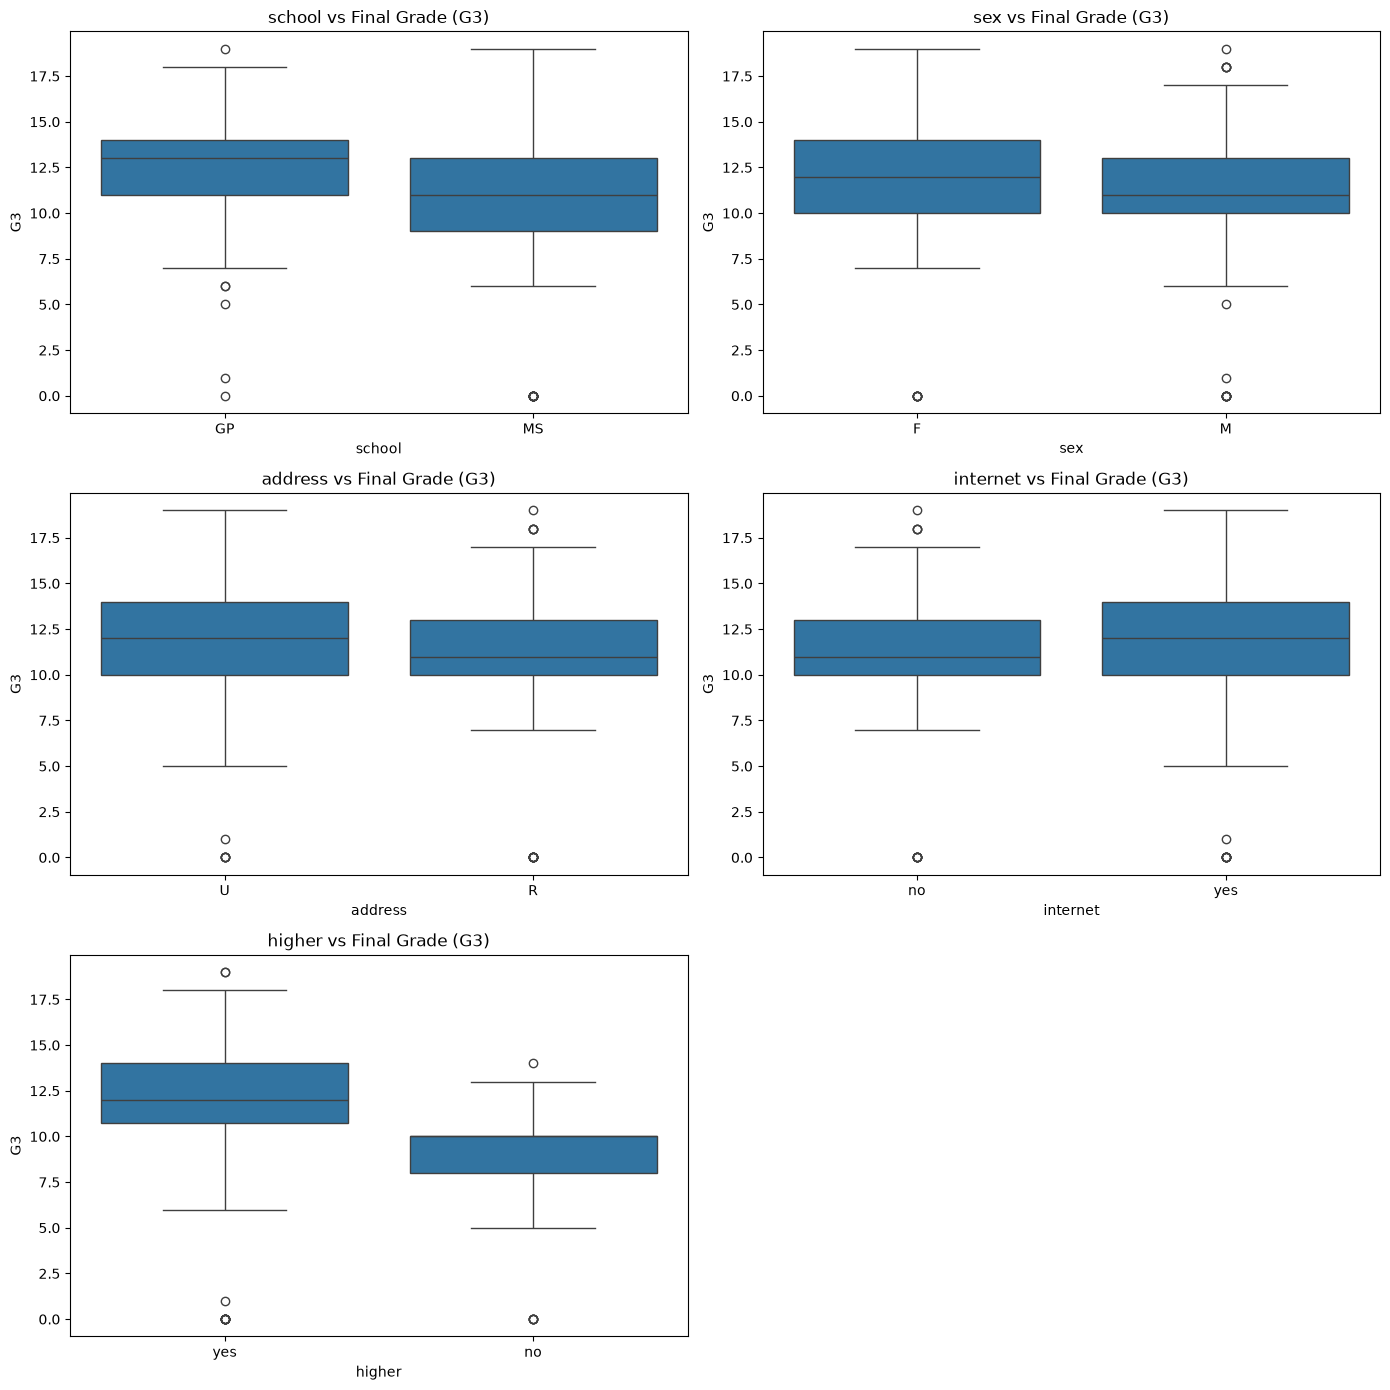

In [39]:
categorical_columns = [
    "school",
    "sex",
    "address",
    "internet",
    "higher"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))

for column, ax in zip(categorical_columns, axes.flatten()):
    sns.boxplot(data=analysis_df, x=column, y="G3", ax=ax)
    ax.set_title(f"{column} vs Final Grade (G3)")

# Remove unused subplot
fig.delaxes(axes[2, 1])

plt.tight_layout()
plt.show()

In [40]:
for column in categorical_columns:
    print(f"\nAverage G3 by {column}:")
    display(
        analysis_df.groupby(column)["G3"]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )


Average G3 by school:


,count,mean,median,std
school,,,,
GP,423,12.58,13.0,2.63
MS,226,10.65,11.0,3.83



Average G3 by sex:


,count,mean,median,std
sex,,,,
F,383,12.25,12.0,3.12
M,266,11.41,11.0,3.32



Average G3 by address:


,count,mean,median,std
address,,,,
R,197,11.09,11.0,3.61
U,452,12.26,12.0,2.99



Average G3 by internet:


,count,mean,median,std
internet,,,,
no,151,11.03,11.0,3.45
yes,498,12.17,12.0,3.12



Average G3 by higher:


,count,mean,median,std
higher,,,,
no,69,8.80,10.0,2.97
yes,580,12.28,12.0,3.06


### Categorical Features vs Final Grade (G3)

1. **School:** GP students have a higher average final grade than MS students. MS students also show greater variation in grades.

2. **Sex:** Female students have a slightly higher average final grade than male students.

3. **Address:** Urban students have a higher average final grade than rural students.

4. **Internet Access:** Students with internet access have a higher average final grade than those without access.

5. **Higher Education Intention:** Students intending to pursue higher education have a substantially higher average final grade than those who do not.

These results show differences in academic performance across groups. They do not establish causal relationships. Group sizes and within-group variation should also be considered.

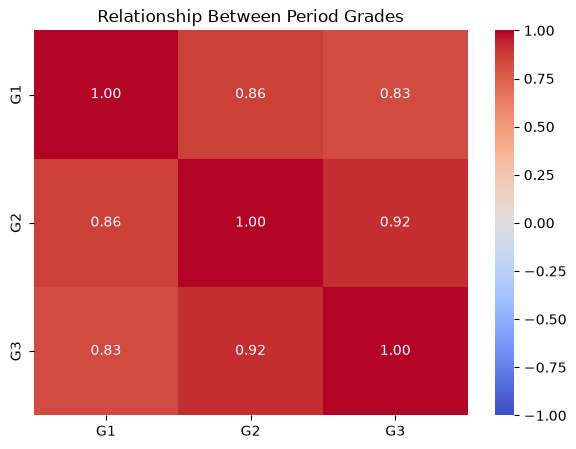

,G1,G2,G3
G1,1.000000,0.864982,0.826387
G2,0.864982,1.000000,0.918548
G3,0.826387,0.918548,1.000000


In [41]:
# Create a DataFrame containing all three period grades
grade_df = X.copy()

grade_df[["G1", "G2", "G3"]] = y[["G1", "G2", "G3"]]

# Calculate correlations
grade_columns = ["G1", "G2", "G3"]

grade_correlation = grade_df[grade_columns].corr()

# Visualize
plt.figure(figsize=(7, 5))

sns.heatmap(
    grade_correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Relationship Between Period Grades")
plt.show()

display(grade_correlation)

### Relationship Between Period Grades

The correlation analysis reveals strong positive relationships between the three academic period grades.

| Relationship | Correlation |
|---|---:|
| G1 vs G2 | 0.86 |
| G1 vs G3 | 0.83 |
| G2 vs G3 | 0.92 |

**Key observations:**

- G1 and G2 are strongly positively correlated.
- Both earlier-period grades are strongly associated with G3.
- G2 has the strongest correlation with G3 (0.92).
- Earlier academic performance may provide valuable predictive information.

**Prediction-time consideration:**

G1 and G2 can be used when predicting G3 after the second period. However, they must be excluded when predicting final performance at the beginning of the academic year because they are not yet available.

Feature selection must reflect the actual prediction scenario to prevent temporal data leakage.

# Overall EDA Conclusions

## 1. Dataset Characteristics

The Student Performance dataset contains academic and demographic information about 649 secondary school students from two Portuguese schools.

It includes 30 input features covering:

- **Demographic information:** Age, sex, address and family size.
- **Family and social background:** Parental education, parental jobs and family relationships.
- **Lifestyle and behaviour:** Study time, free time, going out, alcohol consumption and health.
- **Academic information:** Previous class failures, school support, absences and grades from earlier periods.

The dataset also contains three academic grade variables:

- **G1:** First-period grade.
- **G2:** Second-period grade.
- **G3:** Final-period grade.

G3 is our target variable. It ranges from 0 to 20.

The dataset contains both numerical and categorical features. Some integer-coded variables, such as studytime, failures and parental education, represent discrete or ordinal categories rather than continuous measurements.

## 2. Important Patterns

The exploratory analysis revealed several interesting relationships with G3.

**Earlier Academic Performance**

- G1 has a strong positive correlation with G3 (0.83).
- G2 has a very strong positive correlation with G3 (0.92).
- G2 has the strongest linear association with the final grade among the three grade variables.

**Previous Academic Failures**

- Failures has a moderate negative correlation with G3 (-0.39).
- Most students have zero previous failures.
- Students with more previous failures generally tend to have lower final grades.

**Study Time**

- Studytime has a weak positive correlation with G3 (0.25).
- Students in higher study-time categories generally show somewhat higher final grades.

**Absences and Age**

- Absences has a very weak negative correlation with G3 (-0.09).
- Age has a very weak negative correlation with G3 (-0.11).
- Neither feature shows a strong linear relationship with the final grade in our analysis.

**Categorical Features**

Group comparisons showed differences in average G3:

- GP students had a higher mean grade than MS students.
- Female students had a higher mean grade than male students.
- Urban students had a higher mean grade than rural students.
- Students with internet access had a higher mean grade than those without access.
- Students intending to pursue higher education had a substantially higher mean grade than those who did not.

These differences represent associations and do not establish causal relationships.

## 3. Potential Predictive Features

Based on the EDA, several features are worth investigating in future predictive models.

- **Failures:** Previous academic failures may provide useful information about a student's academic history.
- **Studytime:** Weekly study-time category may provide information about study habits.
- **Absences:** Attendance may provide additional information about student engagement, although its observed linear correlation with G3 is very weak.
- **Higher education intention:** This feature showed a substantial difference in average G3 between its two groups.
- **School and demographic features:** School, address, sex and internet access showed differences in group-level average grades.

G1 and G2 are particularly promising predictors because of their strong correlations with G3. However, their suitability depends on when the prediction is made.

These features are candidates for model experimentation, not proven measures of predictive importance. Their actual usefulness must be evaluated using appropriate validation.

## 4. Limitations

**Limited Geographic Coverage**

The dataset comes from only two secondary schools in Portugal. Its patterns may not generalize to other countries, education systems or student populations.

**Uneven Feature Distributions**

Features such as failures and absences have skewed distributions. Most students report zero previous failures, while a small number have substantially higher absence counts. Models may have less information about these less frequent cases.

**Self-Reported Information**

Several variables, including studytime, family relationships and alcohol consumption, were collected through student questionnaires. Self-reported information may contain inaccurate estimates or reporting bias.

**Prediction-Time Data Leakage**

G1 and G2 are strongly associated with G3. They are legitimate predictors when available before the prediction is made, such as after the second period. However, they must be excluded from an early-year prediction model because they are not yet available.

**Exploratory Analysis Limitations**

EDA identifies patterns and associations but does not establish causation or prove predictive performance. We have not yet trained and evaluated machine learning models, so feature importance and generalization remain to be tested.

**Unequal Group Sizes**

Some categorical groups are considerably smaller than others. Group-level averages should therefore be interpreted alongside sample counts and variation.



In [42]:
additional_features = [
    "Medu",
    "Fedu",
    "goout",
    "Dalc",
    "Walc",
    "health",
    "famrel"
]

additional_corr = analysis_df[additional_features + ["G3"]].corr()

display(
    additional_corr["G3"]
    .drop("G3")
    .sort_values(ascending=False)
    .to_frame("Correlation with G3")
)

,Correlation with G3
Medu,0.240151
Fedu,0.211800
famrel,0.063361
goout,-0.087641
health,-0.098851
Walc,-0.176619
Dalc,-0.204719


### Additional Feature Correlation Analysis

The analysis examined parental education, family relationships, social activities, health and alcohol consumption.

| Feature | Correlation with G3 | Interpretation |
|---|---:|---|
| Medu | +0.24 | Weak positive |
| Fedu | +0.21 | Weak positive |
| famrel | +0.06 | Very weak positive |
| goout | -0.09 | Very weak negative |
| health | -0.10 | Very weak negative |
| Walc | -0.18 | Weak negative |
| Dalc | -0.20 | Weak negative |

**Key observations:**

- Parental education levels show weak positive associations with final grades.
- Family relationship ratings have almost no linear association with G3.
- Going-out frequency and health have very weak negative associations.
- Weekday and weekend alcohol consumption both show weak negative associations with final grades.
- Weekday alcohol consumption has a slightly stronger negative correlation than weekend consumption.

These findings are exploratory. They do not establish causation or prove that these features will improve model predictions. Several variables are ordinal, so Pearson correlation should be interpreted cautiously.

## Prediction Scenario Design

In [43]:
# Target variable: final-period grade
target = y["G3"].copy()

# Experiment A: exclude G1 and G2
X_early = X.copy()

# Experiment B: include G1 and G2
X_late = X.copy()

X_late[["G1", "G2"]] = y[["G1", "G2"]]

# Verify the feature sets
print("Experiment A shape:", X_early.shape)
print("Experiment B shape:", X_late.shape)
print("Target shape:", target.shape)

print("\nExperiment A columns:")
print(X_early.columns.tolist())

print("\nExperiment B columns:")
print(X_late.columns.tolist())

Experiment A shape: (649, 30)
Experiment B shape: (649, 32)
Target shape: (649,)

Experiment A columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Experiment B columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


In [44]:
from sklearn.model_selection import train_test_split

# Generate shared row indices
indices = X.index

train_indices, test_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42
)

# Experiment A
X_early_train = X_early.loc[train_indices]
X_early_test = X_early.loc[test_indices]

# Experiment B
X_late_train = X_late.loc[train_indices]
X_late_test = X_late.loc[test_indices]

# Shared target splits
y_train = target.loc[train_indices]
y_test = target.loc[test_indices]

print("Training samples:", len(train_indices))
print("Testing samples:", len(test_indices))

print("\nExperiment A:")
print(X_early_train.shape, X_early_test.shape)

print("\nExperiment B:")
print(X_late_train.shape, X_late_test.shape)

print("\nTarget:")
print(y_train.shape, y_test.shape)

Training samples: 519
Testing samples: 130

Experiment A:
(519, 30) (130, 30)

Experiment B:
(519, 32) (130, 32)

Target:
(519,) (130,)


In [45]:
# Verify identical train/test splits
print(
    "Training indices identical:",
    X_early_train.index.equals(X_late_train.index)
)

print(
    "Testing indices identical:",
    X_early_test.index.equals(X_late_test.index)
)

# Verify G1 and G2 availability
print(
    "G1 in Experiment A:",
    "G1" in X_early.columns
)

print(
    "G2 in Experiment A:",
    "G2" in X_early.columns
)

print(
    "G1 and G2 in Experiment B:",
    {"G1", "G2"}.issubset(X_late.columns)
)

Training indices identical: True
Testing indices identical: True
G1 in Experiment A: False
G2 in Experiment A: False
G1 and G2 in Experiment B: True


In [46]:
categorical_features = [
    "school", "sex", "address", "famsize", "Pstatus",
    "Mjob", "Fjob", "reason", "guardian",
    "schoolsup", "famsup", "paid", "activities",
    "nursery", "higher", "internet", "romantic"
]

numerical_features = [
    "age", "Medu", "Fedu", "traveltime", "studytime",
    "failures", "famrel", "freetime", "goout",
    "Dalc", "Walc", "health", "absences"
]

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Total:", len(categorical_features) + len(numerical_features))

Categorical features: 17
Numerical features: 13
Total: 30


In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

print("Preprocessing components created.")

Preprocessing components created.


In [48]:
# Experiment A: without G1 and G2
preprocessor_early = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Experiment B: with G1 and G2
late_numerical_features = numerical_features + ["G1", "G2"]

preprocessor_late = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, late_numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Both preprocessors created successfully.")

Both preprocessors created successfully.


In [49]:
# Fit on training data and transform
X_early_train_processed = preprocessor_early.fit_transform(
    X_early_train
)

# Transform test data using training-fitted parameters
X_early_test_processed = preprocessor_early.transform(
    X_early_test
)

# Experiment B
X_late_train_processed = preprocessor_late.fit_transform(
    X_late_train
)

X_late_test_processed = preprocessor_late.transform(
    X_late_test
)

In [50]:
print("Experiment A:")
print("Training:", X_early_train_processed.shape)
print("Testing:", X_early_test_processed.shape)

print("\nExperiment B:")
print("Training:", X_late_train_processed.shape)
print("Testing:", X_late_test_processed.shape)

Experiment A:
Training: (519, 56)
Testing: (130, 56)

Experiment B:
Training: (519, 58)
Testing: (130, 58)


In [51]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_early_train, y_train)

baseline_predictions = baseline.predict(X_early_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Results")
print("----------------")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R²:", baseline_r2)

Baseline Results
----------------
MAE: 2.3946050096339113
RMSE: 3.1725903070595547
R²: -0.032159804579835916


In [52]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# Experiment A: Without previous grades
model_early = Pipeline(
    steps=[
        ("preprocessor", preprocessor_early),
        ("regressor", LinearRegression())
    ]
)

# Experiment B: With previous grades
model_late = Pipeline(
    steps=[
        ("preprocessor", preprocessor_late),
        ("regressor", LinearRegression())
    ]
)

# Train both models
model_early.fit(X_early_train, y_train)
model_late.fit(X_late_train, y_train)

print("Both models trained successfully.")

Both models trained successfully.


In [53]:
# Predictions on the same test samples
predictions_early = model_early.predict(X_early_test)
predictions_late = model_late.predict(X_late_test)

print("Experiment A predictions:", predictions_early[:10])
print("Experiment B predictions:", predictions_late[:10])
print("Actual G3 values:", y_test.iloc[:10].values)

Experiment A predictions: [13.07258168 12.96931302 14.01863908 12.00426682 10.36382675 12.69353688
 13.83268367  6.67335839 12.56000408 12.15618806]
Experiment B predictions: [18.40265613 11.82720849 18.56288575 10.80969554 11.74323992 16.52050538
 17.68642688  9.20547185 10.99263829 10.52990179]
Actual G3 values: [19 12 18 11 11 17 18  8 10 11]


In [54]:
def evaluate_model(y_true, predictions):
    mae = mean_absolute_error(y_true, predictions)
    rmse = np.sqrt(mean_squared_error(y_true, predictions))
    r2 = r2_score(y_true, predictions)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


results_early = evaluate_model(y_test, predictions_early)
results_late = evaluate_model(y_test, predictions_late)

print("Experiment A — Without G1/G2")
print(results_early)

print("\nExperiment B — With G1/G2")
print(results_late)

Experiment A — Without G1/G2
{'MAE': 2.156382187028527, 'RMSE': np.float64(2.86177993773442), 'R2': 0.16016991964318306}

Experiment B — With G1/G2
{'MAE': 0.765059768275826, 'RMSE': np.float64(1.2148700573987046), 'R2': 0.8486513286537314}


In [55]:
comparison = pd.DataFrame({
    "Actual_G3": y_test,
    "Predicted_Early": predictions_early,
    "Predicted_Late": predictions_late
})

comparison["Early_Error"] = (
    comparison["Actual_G3"] - comparison["Predicted_Early"]
)

comparison["Late_Error"] = (
    comparison["Actual_G3"] - comparison["Predicted_Late"]
)

comparison.head(15)

,Actual_G3,Predicted_Early,Predicted_Late,Early_Error,Late_Error
636,19,13.072582,18.402656,5.927418,0.597344
220,12,12.969313,11.827208,-0.969313,0.172792
594,18,14.018639,18.562886,3.981361,-0.562886
429,11,12.004267,10.809696,-1.004267,0.190304
72,11,10.363827,11.743240,0.636173,-0.743240
448,17,12.693537,16.520505,4.306463,0.479495
181,18,13.832684,17.686427,4.167316,0.313573
131,8,6.673358,9.205472,1.326642,-1.205472
231,10,12.560004,10.992638,-2.560004,-0.992638
277,11,12.156188,10.529902,-1.156188,0.470098


In [56]:
comparison["Absolute_Late_Error"] = (
    comparison["Late_Error"].abs()
)

comparison.sort_values(
    by="Absolute_Late_Error",
    ascending=False
).head(10)

,Actual_G3,Predicted_Early,Predicted_Late,Early_Error,Late_Error,Absolute_Late_Error
163,0,6.842334,9.503716,-6.842334,-9.503716,9.503716
642,11,12.537639,8.331395,-1.537639,2.668605,2.668605
518,8,11.528354,5.510911,-3.528354,2.489089,2.489089
557,10,6.586582,7.940765,3.413418,2.059235,2.059235
292,14,13.320298,12.065706,0.679702,1.934294,1.934294
78,10,4.952522,8.212724,5.047478,1.787276,1.787276
344,17,13.206017,18.766473,3.793983,-1.766473,1.766473
367,14,14.042003,12.369034,-0.042003,1.630966,1.630966
444,11,9.290374,9.411084,1.709626,1.588916,1.588916
109,14,13.579757,15.588039,0.420243,-1.588039,1.588039


In [57]:
student_index = 163

print("Actual student features:")
display(X_late_test.loc[[student_index]])

print("Actual and predicted grades:")
display(comparison.loc[[student_index]])

Actual student features:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
163,GP,M,18,U,LE3,T,1,1,other,other,...,yes,2,3,5,2,5,4,0,11,9


Actual and predicted grades:


,Actual_G3,Predicted_Early,Predicted_Late,Early_Error,Late_Error,Absolute_Late_Error
163,0,6.842334,9.503716,-6.842334,-9.503716,9.503716


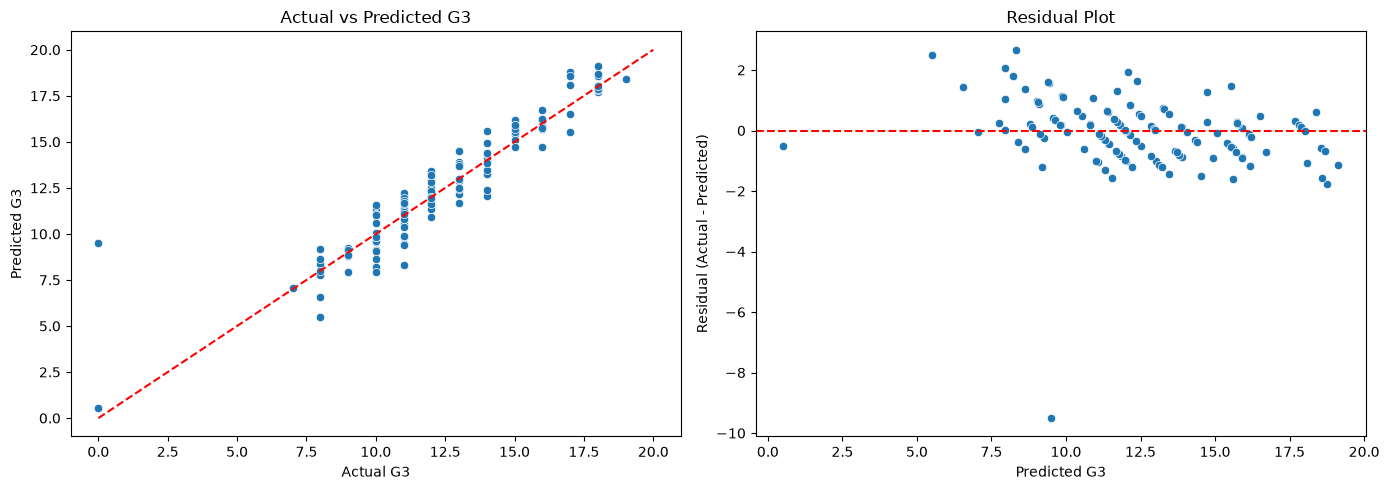

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

residuals = y_test - predictions_late

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs predicted
sns.scatterplot(
    x=y_test,
    y=predictions_late,
    ax=axes[0]
)

axes[0].plot(
    [0, 20],
    [0, 20],
    linestyle="--",
    color="red"
)

axes[0].set_title("Actual vs Predicted G3")
axes[0].set_xlabel("Actual G3")
axes[0].set_ylabel("Predicted G3")

# Residual plot
sns.scatterplot(
    x=predictions_late,
    y=residuals,
    ax=axes[1]
)

axes[1].axhline(
    y=0,
    linestyle="--",
    color="red"
)

axes[1].set_title("Residual Plot")
axes[1].set_xlabel("Predicted G3")
axes[1].set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

In [59]:
columns_to_inspect = [
    "age",
    "failures",
    "studytime",
    "absences",
    "Medu",
    "Fedu",
    "schoolsup",
    "higher",
    "G1",
    "G2"
]

display(X_late_test.loc[[163], columns_to_inspect])

,age,failures,studytime,absences,Medu,Fedu,schoolsup,higher,G1,G2
163,18,2,1,0,1,1,no,no,11,9


In [60]:
print("Students with G3 = 0:", (target == 0).sum())

display(
    X_late.loc[target[target == 0].index, ["G1", "G2", "failures", "absences"]]
    .assign(G3=target[target == 0])
)

Students with G3 = 0: 15


,G1,G2,failures,absences,G3
163,11,9,2,0,0
440,7,0,0,0,0
519,8,7,0,0,0
563,7,0,1,0,0
567,4,0,1,0,0
583,8,6,1,0,0
586,8,8,0,0,0
597,9,0,1,0,0
603,5,0,0,0,0
605,5,0,1,0,0


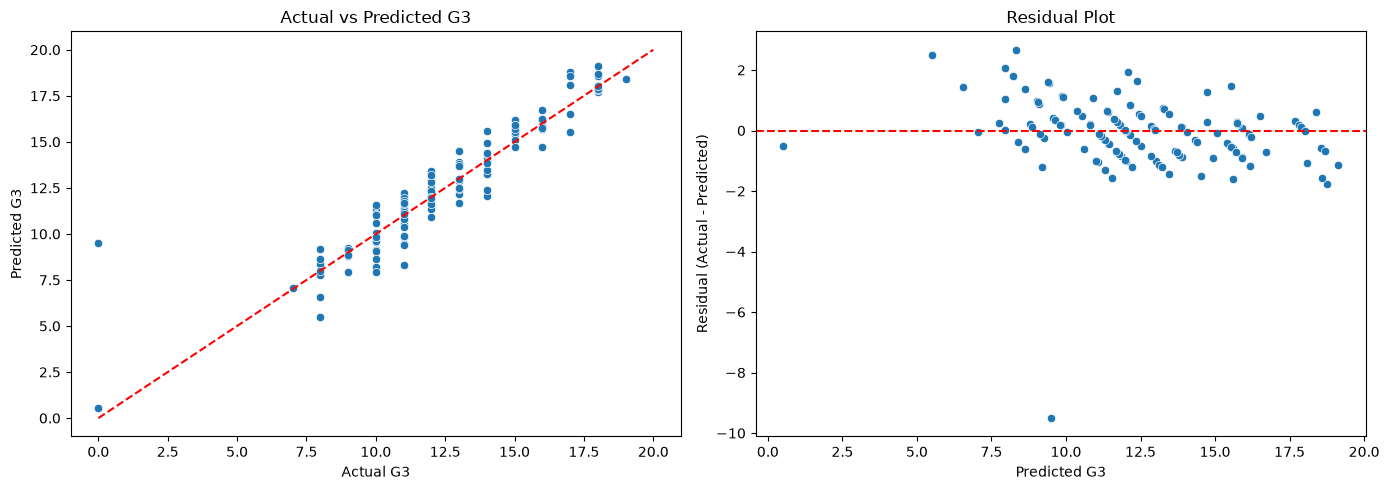

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

residuals = y_test - predictions_late

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs predicted
sns.scatterplot(
    x=y_test,
    y=predictions_late,
    ax=axes[0]
)

axes[0].plot(
    [0, 20],
    [0, 20],
    linestyle="--",
    color="red"
)

axes[0].set_title("Actual vs Predicted G3")
axes[0].set_xlabel("Actual G3")
axes[0].set_ylabel("Predicted G3")

# Residual plot
sns.scatterplot(
    x=predictions_late,
    y=residuals,
    ax=axes[1]
)

axes[1].axhline(
    y=0,
    linestyle="--",
    color="red"
)

axes[1].set_title("Residual Plot")
axes[1].set_xlabel("Predicted G3")
axes[1].set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

In [62]:
print("Residual statistics")
print("-------------------")

print("Mean residual:", residuals.mean())
print("Median residual:", residuals.median())
print("Residual standard deviation:", residuals.std())
print("Minimum residual:", residuals.min())
print("Maximum residual:", residuals.max())

print("\nResidual correlation with predictions:",
      np.corrcoef(predictions_late, residuals)[0, 1])

Residual statistics
-------------------
Mean residual: -0.11048188168068307
Median residual: -0.050266044015342626
Residual standard deviation: 1.2145161773920083
Minimum residual: -9.503716364848179
Maximum residual: 2.6686054705860833

Residual correlation with predictions: -0.2195070216382006


In [63]:
# Extract trained model
linear_model_late = model_late.named_steps["regressor"]

# Get transformed feature names
feature_names = (
    model_late.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Build coefficient DataFrame
coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": linear_model_late.coef_
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

# Largest positive and negative coefficients
print("Largest positive coefficients:")
display(
    coefficients.sort_values(
        "Coefficient",
        ascending=False
    ).head(15)
)

print("Largest negative coefficients:")
display(
    coefficients.sort_values(
        "Coefficient",
        ascending=True
    ).head(15)
)

print("Intercept:", linear_model_late.intercept_)

Largest positive coefficients:


,Feature,Coefficient,Absolute_Coefficient
14,num__G2,2.471735,2.471735
13,num__G1,0.460262,0.460262
30,cat__Fjob_at_home,0.341105,0.341105
41,cat__guardian_other,0.217930,0.217930
26,cat__Mjob_health,0.187043,0.187043
35,cat__reason_course,0.171600,0.171600
15,cat__school_GP,0.152276,0.152276
29,cat__Mjob_teacher,0.146725,0.146725
28,cat__Mjob_services,0.103966,0.103966
46,cat__paid_no,0.096179,0.096179


Largest negative coefficients:


,Feature,Coefficient,Absolute_Coefficient
27,cat__Mjob_other,-0.281778,0.281778
37,cat__reason_other,-0.247110,0.247110
34,cat__Fjob_teacher,-0.194665,0.194665
33,cat__Fjob_services,-0.189525,0.189525
1,num__Medu,-0.166254,0.166254
25,cat__Mjob_at_home,-0.155957,0.155957
16,cat__school_MS,-0.152276,0.152276
5,num__failures,-0.124303,0.124303
7,num__freetime,-0.113908,0.113908
40,cat__guardian_mother,-0.113312,0.113312


Intercept: 11.723234251091437


In [64]:
OneHotEncoder(
    handle_unknown="ignore",
    drop="first"
)

,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",'first'
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",True
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infreq

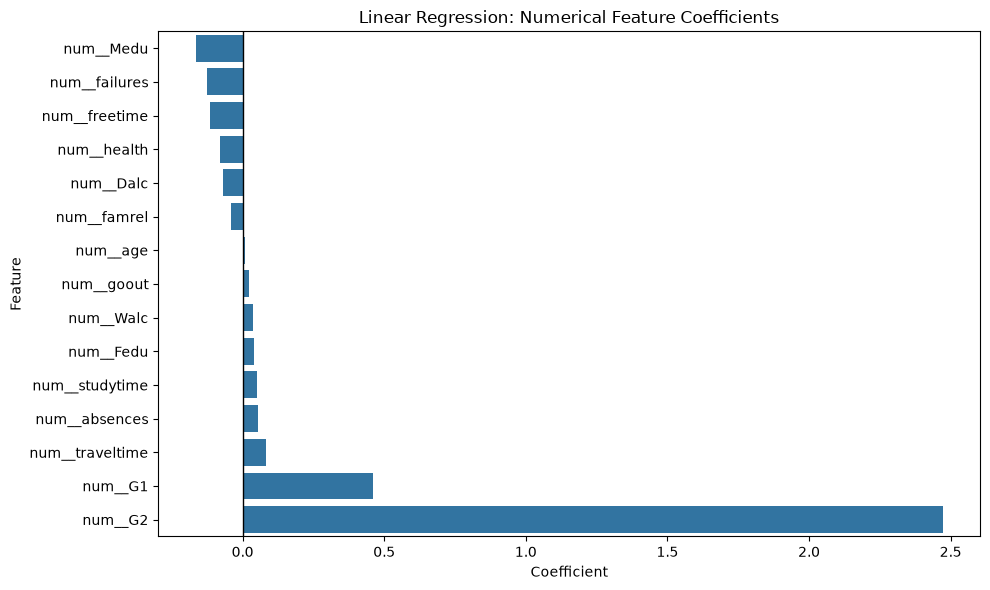

In [65]:
# Numerical feature coefficients
numerical_coefficients = coefficients[
    coefficients["Feature"].str.startswith("num__")
].copy()

numerical_coefficients = numerical_coefficients.sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=numerical_coefficients,
    x="Coefficient",
    y="Feature"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Linear Regression: Numerical Feature Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [66]:
g2_scaler = (
    model_late.named_steps["preprocessor"]
    .named_transformers_["num"]
    .named_steps["scaler"]
)

g2_index = late_numerical_features.index("G2")

g2_std = g2_scaler.scale_[g2_index]

g2_raw_coefficient = (
    linear_model_late.coef_[
        list(feature_names).index("num__G2")
    ] / g2_std
)

print("G2 standard deviation:", g2_std)
print("G2 coefficient on original scale:", g2_raw_coefficient)

G2 standard deviation: 2.8780142429207625
G2 coefficient on original scale: 0.8588336266640644


In [67]:
# New categorical transformer
categorical_transformer_v2 = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            drop="first"
        ))
    ]
)

# Revised Experiment A preprocessor
preprocessor_early_v2 = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer_v2, categorical_features)
    ]
)

# Revised Experiment B preprocessor
preprocessor_late_v2 = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, late_numerical_features),
        ("cat", categorical_transformer_v2, categorical_features)
    ]
)

In [68]:
model_early_v2 = Pipeline(
    steps=[
        ("preprocessor", preprocessor_early_v2),
        ("regressor", LinearRegression())
    ]
)

model_late_v2 = Pipeline(
    steps=[
        ("preprocessor", preprocessor_late_v2),
        ("regressor", LinearRegression())
    ]
)

# Train
model_early_v2.fit(X_early_train, y_train)
model_late_v2.fit(X_late_train, y_train)

# Predict
predictions_early_v2 = model_early_v2.predict(X_early_test)
predictions_late_v2 = model_late_v2.predict(X_late_test)

print("Revised models trained successfully.")

Revised models trained successfully.


In [69]:
results = pd.DataFrame({
    "Model": [
        "Early - Original",
        "Early - Revised",
        "Late - Original",
        "Late - Revised"
    ],
    "MAE": [
        results_early["MAE"],
        mean_absolute_error(y_test, predictions_early_v2),
        results_late["MAE"],
        mean_absolute_error(y_test, predictions_late_v2)
    ],
    "RMSE": [
        results_early["RMSE"],
        np.sqrt(mean_squared_error(y_test, predictions_early_v2)),
        results_late["RMSE"],
        np.sqrt(mean_squared_error(y_test, predictions_late_v2))
    ],
    "R2": [
        results_early["R2"],
        r2_score(y_test, predictions_early_v2),
        results_late["R2"],
        r2_score(y_test, predictions_late_v2)
    ]
})

display(results.round(4))

,Model,MAE,RMSE,R2
0,Early - Original,2.1564,2.8618,0.1602
1,Early - Revised,2.1564,2.8618,0.1602
2,Late - Original,0.7651,1.2149,0.8487
3,Late - Revised,0.7651,1.2149,0.8487


In [70]:
# Extract revised late model
linear_model_late_v2 = (
    model_late_v2.named_steps["regressor"]
)

feature_names_v2 = (
    model_late_v2.named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients_v2 = pd.DataFrame({
    "Feature": feature_names_v2,
    "Coefficient": linear_model_late_v2.coef_
})

coefficients_v2["Absolute_Coefficient"] = (
    coefficients_v2["Coefficient"].abs()
)

print("Largest positive coefficients:")
display(
    coefficients_v2.sort_values(
        "Coefficient", ascending=False
    ).head(15)
)

print("Largest negative coefficients:")
display(
    coefficients_v2.sort_values(
        "Coefficient", ascending=True
    ).head(15)
)

Largest positive coefficients:


,Feature,Coefficient,Absolute_Coefficient
14,num__G2,2.471735,2.471735
13,num__G1,0.460262,0.460262
20,cat__Mjob_health,0.343000,0.343000
32,cat__guardian_other,0.322548,0.322548
23,cat__Mjob_teacher,0.302682,0.302682
22,cat__Mjob_services,0.259923,0.259923
34,cat__famsup_yes,0.120459,0.120459
39,cat__internet_yes,0.112868,0.112868
17,cat__address_U,0.104781,0.104781
3,num__traveltime,0.083662,0.083662


Largest negative coefficients:


,Feature,Coefficient,Absolute_Coefficient
27,cat__Fjob_teacher,-0.535769,0.535769
26,cat__Fjob_services,-0.530630,0.530630
29,cat__reason_other,-0.418710,0.418710
25,cat__Fjob_other,-0.330553,0.330553
24,cat__Fjob_health,-0.308570,0.308570
15,cat__school_MS,-0.304551,0.304551
35,cat__paid_yes,-0.192358,0.192358
1,num__Medu,-0.166254,0.166254
33,cat__schoolsup_yes,-0.157658,0.157658
30,cat__reason_reputation,-0.144015,0.144015


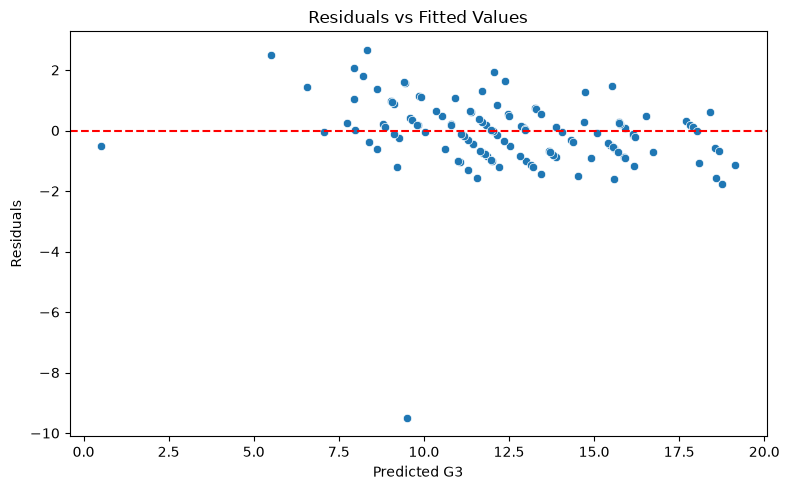

In [71]:
residuals_v2 = y_test - predictions_late_v2

fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    x=predictions_late_v2,
    y=residuals_v2,
    ax=ax
)

ax.axhline(0, linestyle="--", color="red")

ax.set_title("Residuals vs Fitted Values")
ax.set_xlabel("Predicted G3")
ax.set_ylabel("Residuals")

plt.tight_layout()
plt.show()

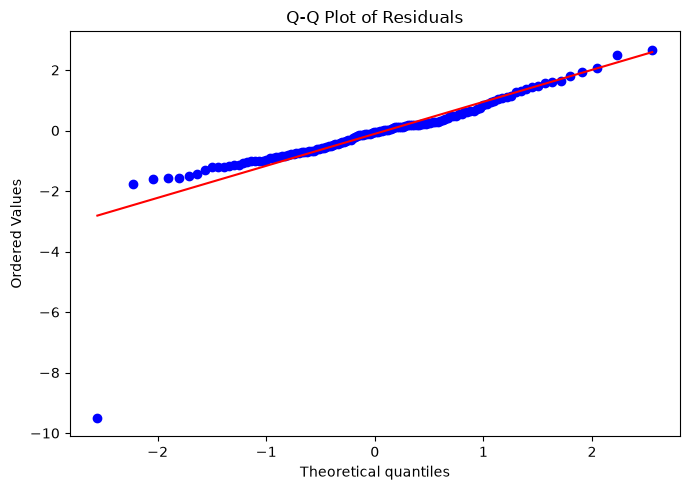

In [72]:
from scipy import stats

fig, ax = plt.subplots(figsize=(7, 5))

stats.probplot(
    residuals_v2,
    dist="norm",
    plot=ax
)

ax.set_title("Q-Q Plot of Residuals")

plt.tight_layout()
plt.show()

In [73]:
# Compare predictions from the original and revised encodings
prediction_difference = np.abs(
    predictions_late - predictions_late_v2
)

print("Maximum prediction difference:",
      prediction_difference.max())

print("Mean prediction difference:",
      prediction_difference.mean())

Maximum prediction difference: 1.4210854715202004e-14
Mean prediction difference: 3.2111065943004528e-15


In [74]:
outlier_index = 163

print("Actual G3:", y_test.loc[outlier_index])
print("Predicted G3:", predictions_late_v2[
    list(y_test.index).index(outlier_index)
])

print("\nStudent features:")
display(X_late.loc[outlier_index].to_frame("Value"))

Actual G3: 0
Predicted G3: 9.503716364848177

Student features:


,Value
school,GP
sex,M
age,18
address,U
famsize,LE3
Pstatus,T
Medu,1
Fedu,1
Mjob,other
Fjob,other
